<a href="https://colab.research.google.com/github/miachen-3/TikTok-Engagement/blob/main/Updated_TikTok_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intro/Objectives:

**Main question:** Among TikTok videos that made it to the trending feed, which characteristics are linked to higher reach (plays) and higher engagement, and how well can we predict either one?


# Data Loading:

In [97]:
import json
import zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

In [98]:
!unzip -o trending.json.zip

Archive:  trending.json.zip
  inflating: trending.json           


In [99]:
#loaded the JSON and flattened it into 1,000 rows and 34 columns
import json
import pandas as pd

with open("trending.json") as f:
    data = json.load(f)

df = pd.json_normalize(data["collector"])
df

,id,text,createTime,webVideoUrl,videoUrl,videoUrlNoWaterMark,diggCount,shareCount,playCount,commentCount,...,musicMeta.playUrl,musicMeta.coverThumb,musicMeta.coverMedium,musicMeta.coverLarge,covers.default,covers.origin,covers.dynamic,videoMeta.height,videoMeta.width,videoMeta.duration
0,6907228749016714497,Confidence went 📈,1608214517,https://www.tiktok.com/@ninakleij/video/690722...,https://v77.tiktokcdn.com/ed1f811617d7b5e18b8d...,,3710,50,44800,68,...,https://sf16-sg.tiktokcdn.com/obj/tos-alisg-v-...,https://p77-sg.tiktokcdn.com/aweme/100x100/tos...,https://p77-sg.tiktokcdn.com/aweme/200x200/tos...,https://p77-sg.tiktokcdn.com/aweme/720x720/tos...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,1024,576,15
1,6875468410612993286,Quiet Zone... follow me on insta: joeysofo. Co...,1600819763,https://www.tiktok.com/@joeysofo/video/6875468...,https://v77.tiktokcdn.com/ab935f1975cb8b69aebf...,,55700,1817,838100,936,...,https://sf77-sg.tiktokcdn.com/obj/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p77-sign-sg.tiktokcdn.com/musically-ma...,https://p77-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/obj/tos-mali...,https://p16-sign-sg.tiktokcdn.com/obj/tos-mali...,https://p16-sign-sg.tiktokcdn.com/obj/tos-mali...,1024,576,11
2,6898699405898059010,Iphone bend test🤗 #tiktok #viral #fyp #iphone ...,1606228625,https://www.tiktok.com/@jackeyephone/video/689...,https://v21.tiktokcdn.com/video/tos/alisg/tos-...,,936200,21100,15300000,27100,...,https://sf16-sg.tiktokcdn.com/obj/tos-alisg-v-...,https://p77-sg.tiktokcdn.com/aweme/100x100/tos...,https://p77-sg.tiktokcdn.com/aweme/200x200/tos...,https://p77-sg.tiktokcdn.com/aweme/720x720/tos...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,960,540,19
3,6902819837345533186,,1607187987,https://www.tiktok.com/@naomivaneeren/video/69...,https://v21.tiktokcdn.com/video/tos/alisg/tos-...,,12900,197,94900,143,...,https://sf16-sg.tiktokcdn.com/obj/musically-ma...,https://p16-sign-va.tiktokcdn.com/musically-ma...,https://p16-sign-va.tiktokcdn.com/musically-ma...,https://p16-sign-va.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,1024,576,13
4,6905635666588192002,小技です👟✨#tiktok教室#tutorial,1607843600,https://www.tiktok.com/@io.dreamer_mk/video/69...,https://v77.tiktokcdn.com/7622979a5ceb97c6da4e...,,8805,198,115300,52,...,https://sf77-sg.tiktokcdn.com/obj/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,1024,576,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6877191692341054721,#foryou #foryoupage,1601220970,https://www.tiktok.com/@artistmiranda/video/68...,https://v77.tiktokcdn.com/12644d87ac40de1c1ab2...,,13300,152,129300,111,...,https://sf77-sg.tiktokcdn.com/obj/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p77-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/musically-ma...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,https://p16-sign-sg.tiktokcdn.com/obj/tos-alis...,1024,576,13
996,6908069845825359109,Stop eating 💩 #gttfg #gotothegym #swolefam #nu...,1608410366,https://www.tiktok.com/@papaswolio/video/69080...,https://v77.tiktokcdn.com/740d0b0889f43900715c...,,12200,223,80700,321,...,https://sf16-sg.tiktokcdn.com/obj/musically-ma...,https://p16-sign-va.tiktokcdn.com/musically-ma...,https://p16-sign-va.tik

In [100]:
df.shape

(1000, 34)

In [101]:
df.columns

Index(['id', 'text', 'createTime', 'webVideoUrl', 'videoUrl',
       'videoUrlNoWaterMark', 'diggCount', 'shareCount', 'playCount',
       'commentCount', 'downloaded', 'mentions', 'hashtags', 'authorMeta.id',
       'authorMeta.secUid', 'authorMeta.name', 'authorMeta.nickName',
       'authorMeta.verified', 'authorMeta.signature', 'authorMeta.avatar',
       'musicMeta.musicId', 'musicMeta.musicName', 'musicMeta.musicAuthor',
       'musicMeta.musicOriginal', 'musicMeta.playUrl', 'musicMeta.coverThumb',
       'musicMeta.coverMedium', 'musicMeta.coverLarge', 'covers.default',
       'covers.origin', 'covers.dynamic', 'videoMeta.height',
       'videoMeta.width', 'videoMeta.duration'],
      dtype='object')

columns include play, like, comment, and share counts, caption text, hashtags, post time, music info, and whether the creator is verified

In [102]:
df.isna().sum()

,0
id,0
text,0
createTime,0
webVideoUrl,0
videoUrl,0
videoUrlNoWaterMark,0
diggCount,0
shareCount,0
playCount,0
commentCount,0


In [103]:
df.groupby("musicMeta.musicOriginal")["playCount"].agg(["median", "count"])

,median,count
musicMeta.musicOriginal,,
False,89750.0,254
True,80500.0,746


746 of 1,000 videos use original sounds, 254 use existing tracks, so the audio-features question will have limited data

# 2. Cleaning and features

**Target variables:**

In [104]:
# Make the two targets we want to predict
df["log_plays"] = np.log10(df["playCount"])
df["total_reactions"] = df["diggCount"] + df["commentCount"] + df["shareCount"]
df["eng_rate"] = df["total_reactions"] / df["playCount"]
print(df[["log_plays", "eng_rate"]].describe())

         log_plays     eng_rate
count  1000.000000  1000.000000
mean      5.050560     0.104102
std       0.682107     0.070857
min       2.667453     0.003541
25%       4.670941     0.054909
50%       4.916453     0.088943
75%       5.340046     0.133090
max       8.399328     0.497349


2a. **Hashtags**

In [105]:
df["tags"] = df["hashtags"].apply(lambda lst: [h["name"].lower() for h in lst])
df["number of hashtags"] = df["hashtags"].apply(lambda x: len(x))
df["number of hashtags"].value_counts().sort_index()

,count
number of hashtags,
0,147
1,57
2,69
3,85
4,91
5,97
6,100
7,69
8,54


**2b.Topic themes**

In [106]:
themes = {
    "anime":    {"anime", "animeedit", "naruto", "otaku", "weeb", "haikyuu", "amv", "animeboy", "kakashi", "waifu"},
    "fitness":  {"fitness", "workout", "gym", "bodybuilding", "powerlifting", "fittok", "deadlift", "powertok",
                 "bodybuilder", "gymshark", "training", "squat", "gains", "strength", "abs", "legday", "exercise", "fit"},
    "horse":    {"horse", "equestrian", "horsegirl"},
    "racing":   {"f1", "formula1", "racing", "mercedes", "redbull"},
    "military": {"army", "marines", "military", "navy", "airforce"},
    "dutch":    {"voorjou", "dutch", "voorjoupagina", "nederland", "netherlands", "viraal", "nederlands", "tiktoknl"},
    "generic_fyp": {"fyp", "foryou", "foryoupage", "fy", "viral", "xyzbca", "foryourpage", "4u", "trending", "fypシ"},
}
for name, tagset in themes.items():
    df["theme_" + name] = df["tags"].apply(lambda t: int(len(set(t) & tagset) > 0))
theme_cols = ["theme_" + n for n in themes]
df[theme_cols].sum()

,0
theme_anime,65
theme_fitness,145
theme_horse,31
theme_racing,25
theme_military,13
theme_dutch,104
theme_generic_fyp,525


**2c. Video age**

In [107]:
# Turn the timestamp into a real date, then work out how old each video is
df["post_time"] = pd.to_datetime(df["createTime"], unit="s")
newest_video = df["post_time"].max()
age = newest_video - df["post_time"]
df["age_days"] = age.dt.days
print(df["age_days"].corr(df["log_plays"]))

-0.07037601006644349


In [108]:
print(df[["log_plays", "eng_rate", "age_days"]].describe())

         log_plays     eng_rate     age_days
count  1000.000000  1000.000000  1000.000000
mean      5.050560     0.104102    41.173000
std       0.682107     0.070857    26.801369
min       2.667453     0.003541     0.000000
25%       4.670941     0.054909    17.000000
50%       4.916453     0.088943    39.000000
75%       5.340046     0.133090    65.000000
max       8.399328     0.497349    89.000000


Relationship between video age and plays is close to zero, so older videos don't have more plays than newer ones. Surprising, because you'd expect time to build up views but good news for our analysis

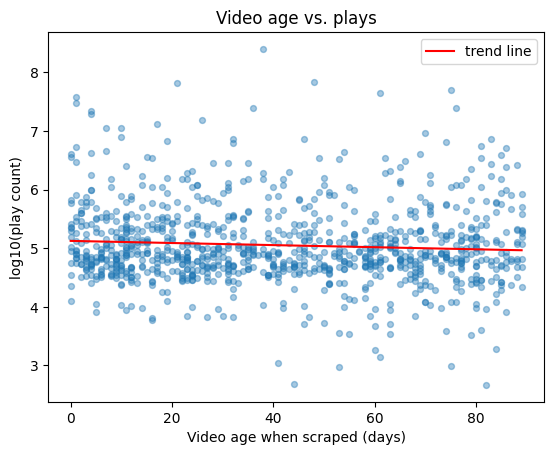

In [109]:
#Scatterplot showing no significant difference between video age and play
import matplotlib.pyplot as plt

plt.scatter(df["age_days"], df["log_plays"], alpha=0.4, s=18)
m, b = np.polyfit(df["age_days"], df["log_plays"], 1)
x = np.linspace(0, df["age_days"].max(), 50)
plt.plot(x, m*x + b, color="red", label="trend line")
plt.xlabel("Video age when scraped (days)")
plt.ylabel("log10(play count)")
plt.title("Video age vs. plays")
plt.legend()
plt.show()

**2d. Other features: **

In [110]:
df["hour"] = df["post_time"].dt.hour
df["weekday"] = df["post_time"].dt.dayofweek
df["duration"] = df["videoMeta.duration"]
df["caption_len"] = df["text"].str.len()
df["verified"] = df["authorMeta.verified"].astype(int)
df["original_sound"] = df["musicMeta.musicOriginal"].astype(int)
df["sound_reuse"] = df.groupby("musicMeta.musicId")["id"].transform("count")

feats = ["age_days", "hour", "weekday", "duration", "caption_len",
         "number of hashtags", "verified", "original_sound", "sound_reuse"]

df[feats + ["log_plays", "eng_rate"]].corr(method="spearman")[["log_plays", "eng_rate"]]

,log_plays,eng_rate
age_days,-0.062452,-0.051199
hour,0.076742,0.056032
weekday,0.024378,0.003015
duration,0.032448,0.193514
caption_len,-0.063992,0.122331
number of hashtags,-0.045001,0.100512
verified,0.257878,0.098791
original_sound,-0.040435,0.106128
sound_reuse,0.022904,-0.035095
log_plays,1.000000,0.031517


Created numeric features from the video, creator, and sound data, then checked each one's rank correlation with log plays and engagement rate

# 3. Exploring data and visuals

**3a. Plays**

In [111]:
df["playCount"].describe()

,playCount
count,1.000000e+03
mean,1.029213e+06
std,9.017676e+06
min,4.650000e+02
25%,4.687500e+04
50%,8.250000e+04
75%,2.188000e+05
max,2.508000e+08


playCount is heavily right-skewed: median= 82.5K but mean= 1.03M, max= 250.8M. We'll want to use a log transform

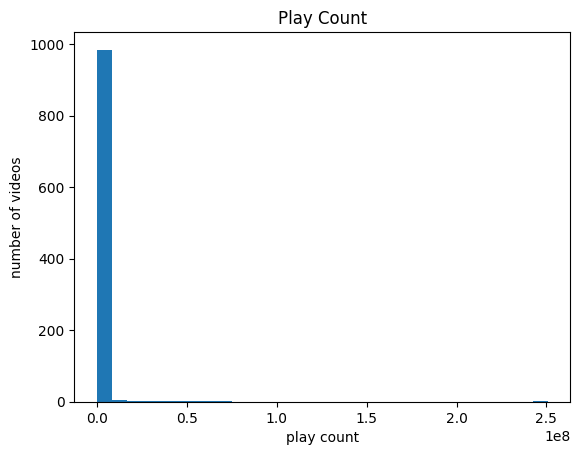

In [112]:
import matplotlib.pyplot as plt

plt.hist(df["playCount"], bins=30)
plt.xlabel("play count")
plt.ylabel("number of videos")
plt.title("Play Count")
plt.show()

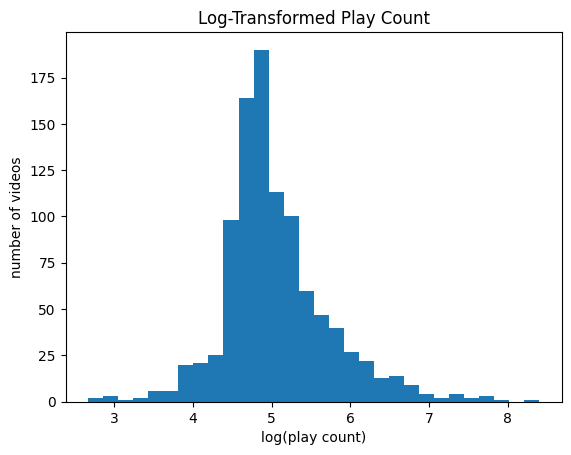

In [113]:
#Aplply log transformation to help w skew
import numpy as np
import matplotlib.pyplot as plt

play_count_log = np.log10(df["playCount"])

plt.hist(play_count_log, bins=30)
plt.xlabel("log(play count)")
plt.ylabel("number of videos")
plt.title("Log-Transformed Play Count")
plt.show()

**3b. Hashtags**

In [114]:
df["hashtags"].head(10)

,hashtags
0,[]
1,[]
2,"[{'id': '23428', 'name': 'tiktok', 'title': ''..."
3,[]
4,"[{'id': '1627704798586882', 'name': 'tiktok教室'..."
5,"[{'id': '9658', 'name': 'volleyball', 'title':..."
6,[]
7,"[{'id': '1677732212525058', 'name': 'timewarps..."
8,"[{'id': '86182714', 'name': 'keşfet', 'title':..."
9,"[{'id': '5436', 'name': 'kids', 'title': '', '..."


Some videos have empty hashtag lists, so hashtag count can be 0

Some names aren't English (tiktok教室 is Chinese, keşfet is Turkish). So some videos come from creators in different countries and languages

In [115]:
df.groupby("number of hashtags")["playCount"].median()

,playCount
number of hashtags,
0,81600.0
1,81200.0
2,191400.0
3,95800.0
4,70100.0
5,76900.0
6,77600.0
7,75300.0
8,82400.0


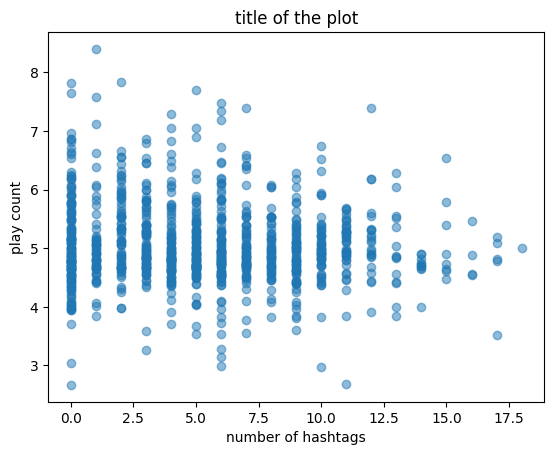

In [116]:
play_count_log = np.log10(df["playCount"])
plt.scatter(df["number of hashtags"],play_count_log , alpha=0.5)
plt.xlabel("number of hashtags")
plt.ylabel("play count")
plt.title("title of the plot")
plt.show()

In [117]:
df["number of hashtags"].corr(play_count_log)

np.float64(-0.08604866738587384)

Median plays are roughly flat across hashtag counts (about 70K to 90K for most), with a few higher groups that have few videos. Hashtag count alone doesn't seem to be strongly related to plays among these trending videos (correlation close to 0)

**3e. Music (original sound vs existing)**

/tmp/ipykernel_2298/979939278.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([group_a, group_b], labels=["original sound", "existing song"])


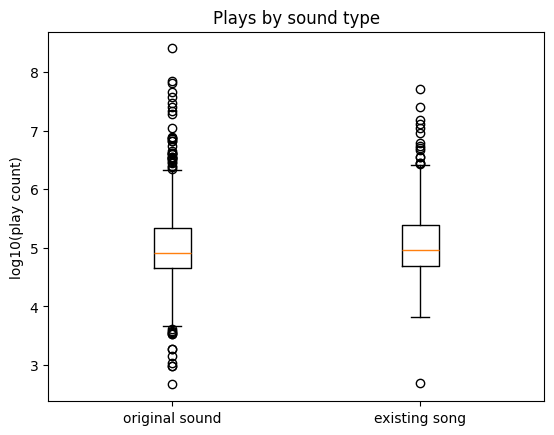

In [118]:
group_a = play_count_log[df["musicMeta.musicOriginal"] == True]
group_b = play_count_log[df["musicMeta.musicOriginal"] == False]

plt.boxplot([group_a, group_b], labels=["original sound", "existing song"])
plt.ylabel("log10(play count)")
plt.title("Plays by sound type")
plt.show()

Boxplots of log plays for original vs. existing sounds overlap almost completely, with medians around 80K to 90K. Sound type alone doesn't separate high from low play

Dataset #2: Songs

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

df_songs = pd.read_csv("TikTok_songs_2020.csv")

print(f"Shape of the dataset -> {df_songs.shape}")
df_songs.head()

Shape of the dataset -> (292, 18)


,track_name,artist_name,artist_pop,album,track_pop,danceability,energy,loudness,mode,key,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,duration_ms
0,Say So,Doja Cat,88,Hot Pink,80,0.787,0.673,-4.583,0,11,0.1590,0.26400,0.000003,0.0904,0.779,110.962,4,237893
1,Blinding Lights,The Weeknd,93,After Hours,90,0.514,0.730,-5.934,1,1,0.0598,0.00146,0.000095,0.0897,0.334,171.005,4,200040
2,Supalonely (feat. Gus Dapperton),BENEE,67,Hey u x,63,0.862,0.631,-4.746,1,7,0.0515,0.29100,0.000209,0.1230,0.841,128.978,4,223488
3,Savage,Megan Thee Stallion,82,Suga,70,0.843,0.741,-5.609,1,11,0.3340,0.02520,0.000000,0.0960,0.680,168.983,4,155497
4,Moral of the Story,Ashe,68,Moral of the Story,76,0.572,0.406,-8.624,1,10,0.0427,0.58700,0.000004,0.1020,0.265,119.812,4,201084


In [121]:
df_songs.shape

(292, 18)

In [122]:
df_existing = df[df["musicMeta.musicOriginal"] == False].copy()
df_existing.shape

(254, 55)

In [123]:
df_existing["song_clean"] = df_existing["musicMeta.musicName"].str.lower().str.strip()
df_songs["song_clean"] = df_songs["track_name"].str.lower().str.strip()
print(df_existing["song_clean"].head())
print(df_songs["song_clean"].head())

0                     element
2     pilfingerdansen - remix
5                    diamonds
8                    believer
10                without you
Name: song_clean, dtype: object
0                              say so
1                     blinding lights
2    supalonely (feat. gus dapperton)
3                              savage
4                  moral of the story
Name: song_clean, dtype: object


In [124]:
matches = df_existing["song_clean"].isin(df_songs["song_clean"])
matches.sum()

np.int64(17)

In [125]:
df_existing[matches][["musicMeta.musicName", "musicMeta.musicAuthor"]]

,musicMeta.musicName,musicMeta.musicAuthor
38,Falling,Trevor Daniel
82,Lets Link,WhoHeem
87,Always Forever,Cults
143,Trampoline,SHAED
182,Boss Bitch,Doja Cat
225,Buttercup,Jack Stauber
240,Kolors,Monte Booker & Smino
270,Lalala,Y2K & bbno$
289,Toosie Slide,Drake
339,Crisis,Jasiah


In [126]:
df_existing[~matches][["musicMeta.musicName", "musicMeta.musicAuthor"]].head(20)

,musicMeta.musicName,musicMeta.musicAuthor
0,Element,Pop Smoke
2,Pilfingerdansen - Remix,Sigurd Barrett
5,Diamonds,Sam Smith
8,Believer,Imagine Dragons
10,WITHOUT YOU,The Kid LAROI
12,Jailhouse Rock,Elvis Presley
21,Original Sound,Unknown
22,Blow Your Mind (Mwahchallenge),Dua Lipa
28,Oh No,Kreepa
30,Say So (Instrumental Version) [Originally Perf...,Elliot Van Coup


We tried to join the videos to the 2020 popular-songs table by song name. Only 17 of 254 existing-song videos matched, which is too few to model, so we dropped audio features

Dataset #3 songs (better match)

In [127]:
songs = pd.read_csv("data.csv")

# 1. Clean titles: lowercase, remove anything in brackets, strip spaces
def simple_title(s):
    return s.astype(str).str.lower().str.replace(r"\(.*?\)|\[.*?\]", "", regex=True).str.strip()

songs["title_key"] = simple_title(songs["name"])
songs["artist_key"] = (songs["artists"].str.replace(r"[\[\]']", "", regex=True)
                       .str.split(",").str[0].str.lower().str.strip())

# many songs appear several times, so keep the most popular version of each
songs = songs.sort_values("popularity", ascending=False).drop_duplicates(["title_key", "artist_key"])

df["title_key"] = simple_title(df["musicMeta.musicName"])
df["artist_key"] = df["musicMeta.musicAuthor"].astype(str).str.lower().str.strip()

# 2. Join the audio features onto the videos
audio_cols = ["danceability", "energy", "valence", "tempo", "loudness", "speechiness", "acousticness"]
df = df.drop(columns=audio_cols, errors="ignore")   # lets this cell be re-run safely
df = df.merge(songs[["title_key", "artist_key"] + audio_cols], on=["title_key", "artist_key"], how="left")

print("videos with audio features:", df["danceability"].notna().sum())
print("rows:", len(df))   # should still be 1000

videos with audio features: 112
rows: 1000


In [128]:
audio_df = df.dropna(subset=["danceability"])
print(len(audio_df), "videos with audio features")
audio_df[audio_cols + ["log_plays", "eng_rate"]].corr(method="spearman")[["log_plays", "eng_rate"]].round(2)

112 videos with audio features


,log_plays,eng_rate
danceability,0.06,0.07
energy,-0.08,-0.11
valence,0.03,0.06
tempo,0.03,0.03
loudness,-0.12,-0.11
speechiness,0.10,-0.00
acousticness,-0.07,0.06
log_plays,1.00,-0.06
eng_rate,-0.06,1.00


For the 112 existing-song videos matched to Spotify audio features, no feature (danceability, energy, valence, tempo, loudness, speechiness, acousticness) had a meaningful rank correlation with log plays or engagement rate

# Modeling and cross- validation:

In [119]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

target = "eng_rate"

X = df[feats].fillna(0)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Baseline":      make_pipeline(StandardScaler(), DummyRegressor()),
    "Lasso":         make_pipeline(StandardScaler(), LassoCV(cv=5)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "test R2:", round(r2_score(y_test, model.predict(X_test)), 3))

Baseline test R2: -0.001
Lasso test R2: 0.038
Random Forest test R2: 0.014


In [129]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

target = "log_plays"

X = df[feats].fillna(0)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Baseline":      make_pipeline(StandardScaler(), DummyRegressor()),
    "Lasso":         make_pipeline(StandardScaler(), LassoCV(cv=5)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "test R2:", round(r2_score(y_test, model.predict(X_test)), 3))

Baseline test R2: -0.001
Lasso test R2: 0.147
Random Forest test R2: 0.092


Using only surface features (posting time, video age, duration, caption length, hashtag count, verified status, sound type, sound reuse), the best model (Lasso) explains about 15% of the variation in log plays and under 4% of engagement rate. A baseline that predicts the mean scores 0, so these models capture a small amount of real signal, but surface features are weak predictors overall

In [131]:
#cross validation
from sklearn.model_selection import cross_val_score, KFold

X = df[feats].fillna(0)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# uses the same `models` dictionary from your previous cell
for target in ["log_plays", "eng_rate"]:
    print(target)
    for name, model in models.items():
        scores = cross_val_score(model, X, df[target], cv=cv, scoring="r2")
        print(f"  {name:14s} mean R2 = {scores.mean():.3f}  (std {scores.std():.3f})")

log_plays
  Baseline       mean R2 = -0.009  (std 0.009)
  Lasso          mean R2 = 0.088  (std 0.057)
  Random Forest  mean R2 = 0.063  (std 0.064)
eng_rate
  Baseline       mean R2 = -0.018  (std 0.019)
  Lasso          mean R2 = 0.030  (std 0.011)
  Random Forest  mean R2 = 0.025  (std 0.033)


In [133]:
summary = []
for name in themes:
    has = df["theme_" + name] == 1
    summary.append({"theme": name, "n_videos": has.sum(),
                    "median_log_plays": df.loc[has, "log_plays"].median(),
                    "median_eng_rate": df.loc[has, "eng_rate"].median()})
summary.append({"theme": "ALL VIDEOS", "n_videos": len(df),
                "median_log_plays": df["log_plays"].median(), "median_eng_rate": df["eng_rate"].median()})
pd.DataFrame(summary).round(3)

,theme,n_videos,median_log_plays,median_eng_rate
0,anime,65,5.014,0.212
1,fitness,145,4.910,0.077
2,horse,31,4.896,0.148
3,racing,25,5.055,0.087
4,military,13,4.906,0.115
5,dutch,104,4.903,0.079
6,generic_fyp,525,4.925,0.086
7,ALL VIDEOS,1000,4.916,0.089


Anime and horse seem to be significant with increase of engagaement rate

# Takeaways so far:

- fyp and other generic hashtags do nothing among trending videos. Many creators believe the opposite, so very surprising find
- Views and reactions are almost unrelated (correlation 0.03). People tend to assume a video with more views also gets more reactions per viewer, and here it doesn't.
- Reach was nearly unpredictable from everything we measured, including posting time, length, hashtag count, and sound type. A lot of TikTok advice is built on those, so surprising find
- Videos with original sounds weren't different from videos with existing songs, which also runs against what many creators assume.
